In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT / "tests"))
TABLES, FIGS, PROC = ROOT / "reports/tables", ROOT / "reports/figures", ROOT / "data/processed"
from olpred.viz import style; style.apply()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

def show(name, width=820):
    display(Image(filename=str(FIGS / name), width=width))

def table(name, **kw):
    return pd.read_csv(TABLES / name, **kw)


# 07 — Monte Carlo season simulation
Method and backtest: `docs/phase9_season_simulation.md`. Needs `make pipeline` (production model and team state).

In [2]:
import joblib
from olpred.predict.league import fit_poisson, league_input, selected_sigma, spots_for
from olpred.predict.simulate import simulate_season, summarise
prod = joblib.load(ROOT / "models_store/production.joblib")
matches = pd.read_parquet(PROC / "matches.parquet"); feats = pd.read_parquet(PROC / "features.parquet")
state = pd.read_parquet(PROC / "team_state.parquet")
season = int(matches.season.max()); played = matches[(matches.season == season) & (matches.league == "F1")]
inp = league_input("F1", played, state, prod["logreg"], fit_poisson(feats[feats.season >= 2011]))
print(f"{len(inp.fixtures)} matches left, Elo sigma = {selected_sigma()}, state as of {prod['as_of']:%Y-%m-%d}")

243 matches left, Elo sigma = 60.0, state as of 2026-10-26


/home/user/ML-PREDICTION-OLYMPIQUE-LYONNAIS/src/olpred/predict/state.py:81: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{f}"] = out[f"h_{f}"] - out[f"a_{f}"]
/home/user/ML-PREDICTION-OLYMPIQUE-LYONNAIS/src/olpred/predict/state.py:81: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"d_{f}"] = out[f"h_{f}"] - out[f"a_{f}"]
/home/user/ML-PREDICTION-OLYMPIQUE-LYONNAIS/src/olpred/predict/state.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, whic

A small run (2,000 simulations) reproduces the saved 10,000-simulation results up to Monte Carlo noise:

In [3]:
res = simulate_season(inp, n_sims=2000, sigma=selected_sigma(), seed=1)
small = summarise(res, inp.teams, spots_for("F1")).sort_values("exp_position")
saved = pd.read_csv(TABLES / "sim_F1_summary.csv", index_col=0)
cmp_ = small[["exp_points", "p_top4"]].join(saved[["exp_points", "p_top4"]], rsuffix=" (10,000 sims)")
cmp_.round(3).head(8)

/tmp/ipykernel_3497/1188772341.py:4: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  cmp_ = small[["exp_points", "p_top4"]].join(saved[["exp_points", "p_top4"]], rsuffix=" (10,000 sims)")


,exp_points,p_top4,"exp_points (10,000 sims)","p_top4 (10,000 sims)"
team,,,,
Paris SG,71.758,0.982,71.925,0.985
Monaco,59.953,0.618,59.873,0.623
Lille,58.948,0.561,58.992,0.566
Lyon,57.726,0.500,57.624,0.504
Paris FC,54.832,0.328,54.833,0.322
Rennes,54.320,0.295,54.307,0.306
Marseille,53.348,0.273,53.015,0.253
Lens,53.347,0.264,53.229,0.258


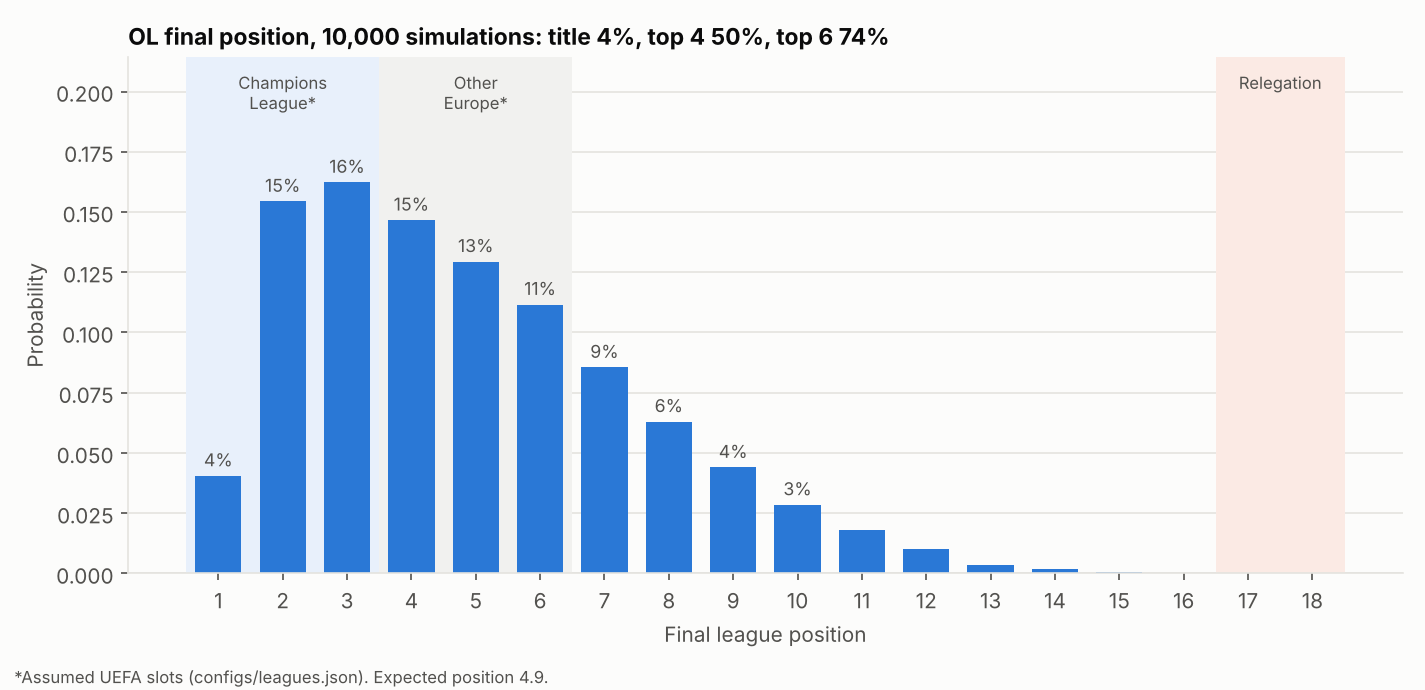

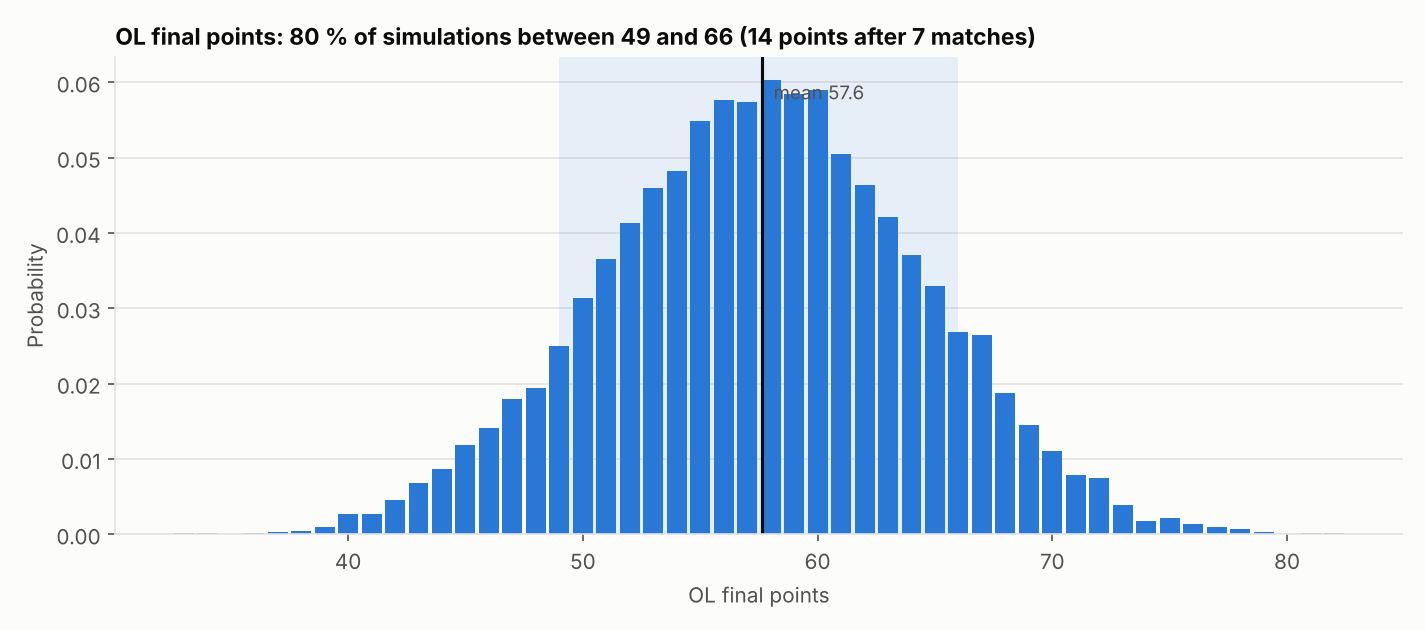

In [4]:
show("sim_ol_position.png"); show("sim_ol_points.png")

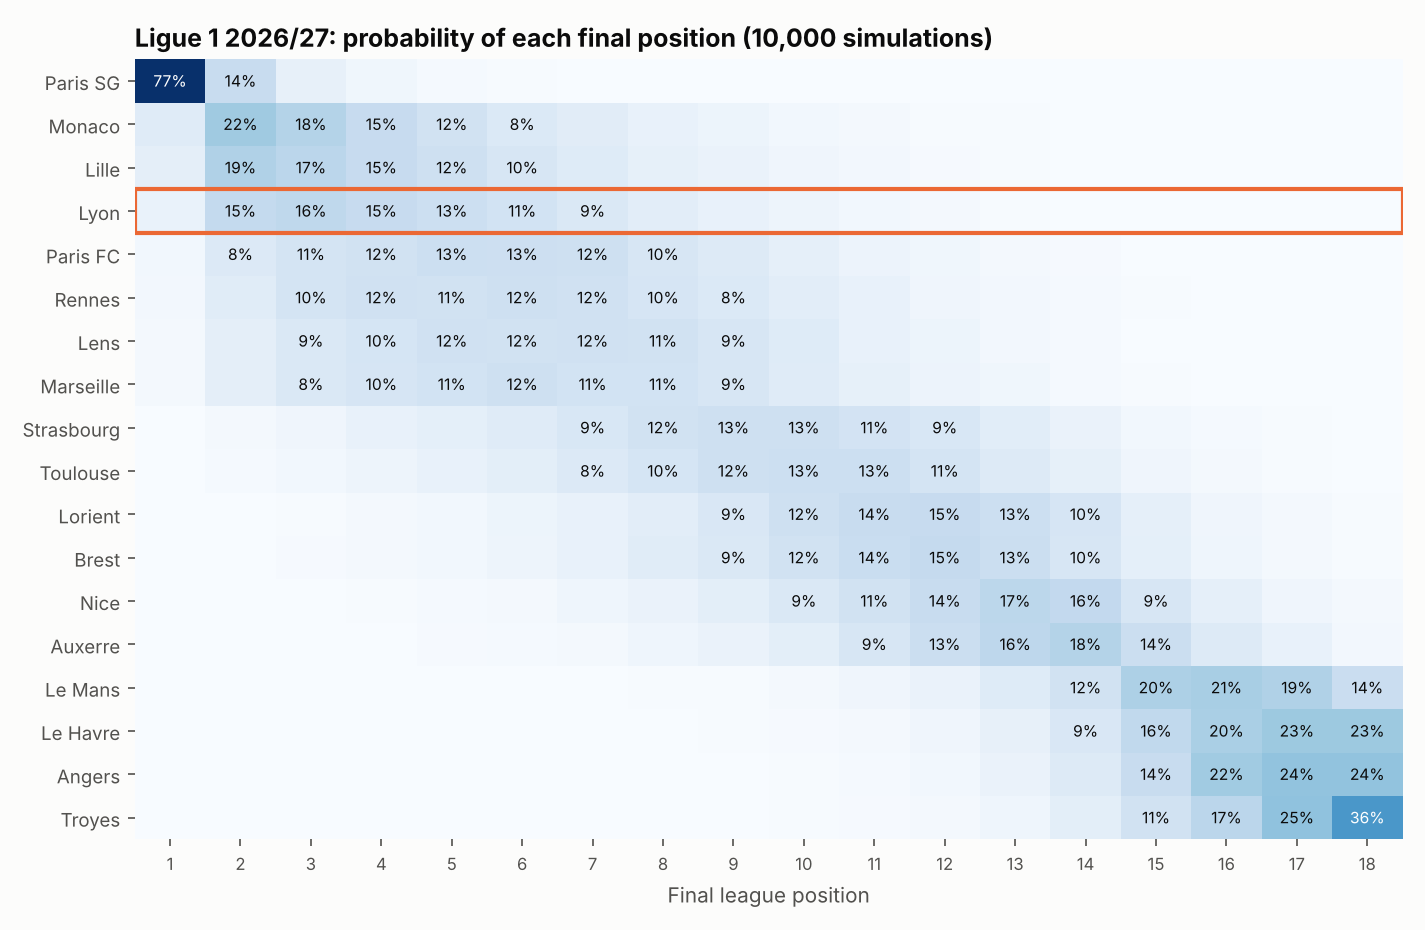

In [5]:
show("sim_league_heatmap.png", 900)

### Backtest of the simulator (2023–2025, five leagues)

,2023,2024,2025,all test seasons
mae_points,6.227,6.585,6.264,6.359
rmse_points,7.912,8.169,7.674,7.921
mae_points_ppg_baseline,8.816,8.212,9.684,8.904
coverage_80,0.750,0.708,0.708,0.722
brier_title,0.023,0.024,0.018,0.022
brier_title_climatology,0.049,0.049,0.049,0.049
brier_top4,0.059,0.055,0.078,0.064
brier_top4_climatology,0.165,0.165,0.165,0.165
brier_top6,0.084,0.092,0.092,0.089
brier_top6_climatology,0.215,0.215,0.215,0.215


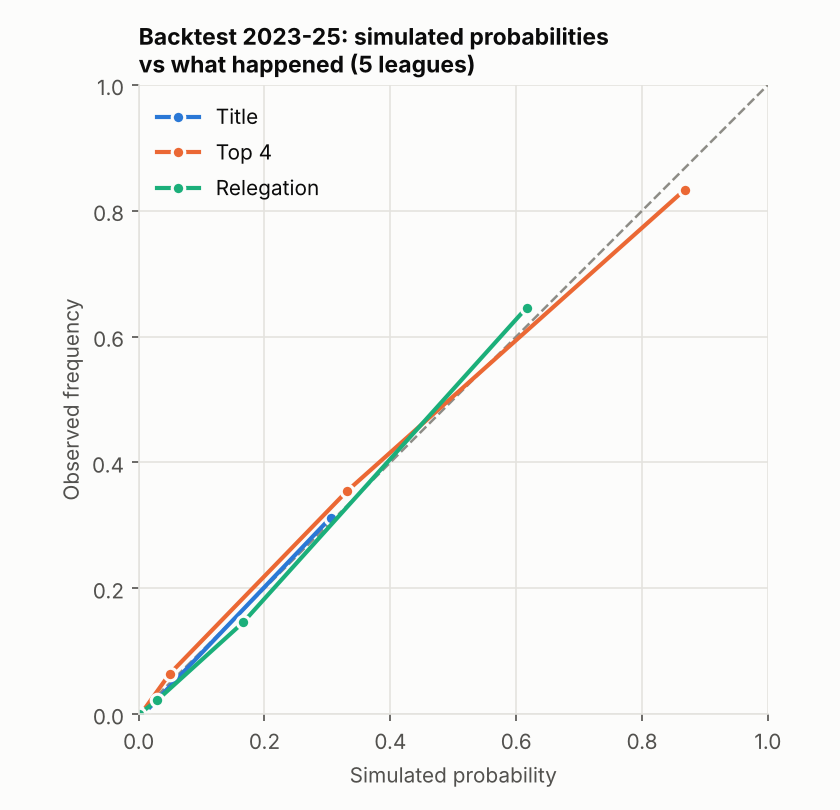

In [6]:
display(table("backtest_eval.csv", index_col=0).T.round(3)); show("sim_backtest_calibration.png", 460)